## QA: upfront_costs_by_building_appliance_upgrade

Do some basic checks on the contents of `prepared.san_jose_ca_2025_s2.upfront_costs_by_building_appliance_upgrade`.


In [0]:
import pyspark.sql.functions as F

from dmlutils.building_upgrades import upgrades
from dmlutils import qa_utils

In [0]:
upfront_costs = spark.table("prepared.san_jose_ca_2025_s2.upfront_costs_by_building_appliance_upgrade")

building_metadata = spark.table("processed.san_jose_ca_2025_s2.building_metadata")
all_building_ids = list(building_metadata.select("building_id").toPandas()["building_id"])

building_set = upgrades.BuildingSet.SAN_JOSE_CA_2025_S2
valid_upgrades = upgrades.REGIONAL_UPGRADES.get(building_set, upgrades.UPGRADES)
valid_upgrade_ids = [u.get("upgrade_id") for u in valid_upgrades]

In [0]:
%sql
CREATE TEMPORARY VIEW t 
AS SELECT * FROM prepared.san_jose_ca_2025_s2.upfront_costs_by_building_appliance_upgrade;

Show the table schema and some sample data.

In [0]:
%sql
DESCRIBE prepared.san_jose_ca_2025_s2.upfront_costs_by_building_appliance_upgrade;

col_name,data_type,comment
building_id,bigint,null
upgrade_id,string,null
appliance_option,string,null
upfront_cost_20percentile,double,null
upfront_cost_median,double,null
upfront_cost_80percentile,double,null
solar_upgrade_id,double,null


In [0]:
%sql
-- Count of buildings for each upgrade
SELECT appliance_option, upgrade_id, solar_upgrade_id, count(1)
FROM t
GROUP BY 1,2,3
ORDER BY 1,2,3;

appliance_option,upgrade_id,solar_upgrade_id,count(1)
240V Circuit,null,null,151498
Basic Weatherization,null,null,151498
"Compact, Battery Electric Vehicle, 200 mile range",null,null,151498
"Compact, Battery Electric Vehicle, 300 mile range",null,null,151498
Electric Resistance Dryer,null,null,151498
Electric Resistance Range,null,null,151498
Enhanced Weatherization,null,null,151498
Heat Pump Dryer,null,null,151498
Heat Pump Water Heater,null,null,151498
Induction Range,null,null,151498


In [0]:
%sql
-- Look at the range of costs for each upgrade
SELECT appliance_option,
       upgrade_id,
       solar_upgrade_id,
       ROUND(MIN(LEAST(upfront_cost_20percentile, upfront_cost_median)), 2) AS min_cost,
       ROUND(MAX(GREATEST(upfront_cost_80percentile, upfront_cost_median)), 2) AS max_cost
FROM prepared.san_jose_ca_2025_s2.upfront_costs_by_building_appliance_upgrade
GROUP BY 1,2,3
ORDER BY 1,2,3;

appliance_option,upgrade_id,solar_upgrade_id,min_cost,max_cost
240V Circuit,null,null,976.17,2921.66
Basic Weatherization,null,null,839.01,104351.13
"Compact, Battery Electric Vehicle, 200 mile range",null,null,0.0,62300.0
"Compact, Battery Electric Vehicle, 300 mile range",null,null,0.0,52318.0
Electric Resistance Dryer,null,null,0.0,400.0
Electric Resistance Range,null,null,600.0,600.0
Enhanced Weatherization,null,null,839.01,219443.1
Heat Pump Dryer,null,null,1400.0,1400.0
Heat Pump Water Heater,null,null,4201.53,8085.59
Induction Range,null,null,0.0,1000.0


In [0]:
%sql
-- Look at a sample building - order from least to most expensive
SELECT *
FROM t
WHERE building_id = 10
order by upfront_cost_median;

building_id,upgrade_id,appliance_option,upfront_cost_20percentile,upfront_cost_median,upfront_cost_80percentile,solar_upgrade_id
10,null,Electric Resistance Dryer,0.0,0.0,0.0,null
10,null,Electric Resistance Range,600.0,600.0,600.0,null
10,null,Induction Range,1000.0,1000.0,1000.0,null
10,null,Ventless Heat Pump Dryer,1400.0,1400.0,1400.0,null
10,null,Heat Pump Dryer,1400.0,1400.0,1400.0,null
10,null,Light-touch air sealing Weatherization,null,1632.4982850307463,null,null
10,null,240V Circuit,976.1738782380721,1915.5344468430112,2921.657410648577,null
10,null,L2 EV Charger,1389.9314148829767,1985.4009472894581,5956.202841868375,null
10,null,Panel Upgrade,1507.5178035607125,5276.312312462493,7537.589017803562,null
10,null,Heat Pump Water Heater,4201.533363712845,5963.385097428103,8085.59216875101,null


In [0]:
%sql
-- Check how often the cost is $0
-- For some upgrade types, this implies that the home already had the relevant appliance
SELECT appliance_option, COUNT(1)
FROM t
WHERE upfront_cost_median = 0
GROUP BY 1;

appliance_option,count(1)
"Compact, Battery Electric Vehicle, 300 mile range",6146
Electric Resistance Dryer,65426
"Compact, Battery Electric Vehicle, 200 mile range",2066
Induction Range,4294
"Midsize, Battery Electric Vehicle, 200 mile range",515
"Pickup, Battery Electric Vehicle, 300 mile range",122
"Pickup, Battery Electric Vehicle, 200 mile range",1
"Midsize, Battery Electric Vehicle, 300 mile range",1422
"SUV, Battery Electric Vehicle, 200 mile range",2172
"SUV, Battery Electric Vehicle, 300 mile range",5605


Check primary keys, including:
- Building IDs are valid (appear in building metadata)
- No duplicate primary key combinations

In [0]:
# Check that all building IDs are valid
assert upfront_costs.where(~F.col("building_id").isin(all_building_ids)).isEmpty()

# Check for duplicate primate keys
qa_utils.assert_unique_primary_key(
    upfront_costs, ["building_id", "appliance_option", "upgrade_id", "solar_upgrade_id"]
)

Columns with null values: {'upgrade_id': 3304242, 'solar_upgrade_id': 3729674}
Validation Successful: All 3913116 rows are unique on ['building_id', 'appliance_option', 'upgrade_id', 'solar_upgrade_id'].


Check that costs are resonable:
- Never negative
- Median falls between the 20th and 80th percentiles

In [0]:
# List of conditions that should not happen
for condition in [
    "upfront_cost_20percentile < 0",
    "upfront_cost_80percentile < 0",
    "upfront_cost_median < 0",
    "upfront_cost_20percentile > upfront_cost_median",
    "upfront_cost_median > upfront_cost_80percentile",
]:
    filtered_upfront_costs = upfront_costs.where(condition)
    if not filtered_upfront_costs.isEmpty():
        display(filtered_upfront_costs.limit(10))
    assert filtered_upfront_costs.isEmpty(), f"Found {filtered_upfront_costs.count()} rows with {condition}"

Check that upgrade IDs and solar upgrade IDs are valid.

In [0]:
assert upfront_costs.where("solar_upgrade_id not in (null, 1, 2)").isEmpty()
assert upfront_costs.where(~F.col("upgrade_id").isin(valid_upgrade_ids)).isEmpty()

In [0]:
assert not qa_utils.check_for_null_values(
    upfront_costs.select(
        "building_id",
        "appliance_option",
        "upfront_cost_median",
        # "upfront_cost_20percentile",
        # "upfront_cost_80percentile",
    )
)

Check whether costs seem reasonable and correlate with other building features.

<Axes: xlabel='system_size_kw', ylabel='upfront_cost_median'>

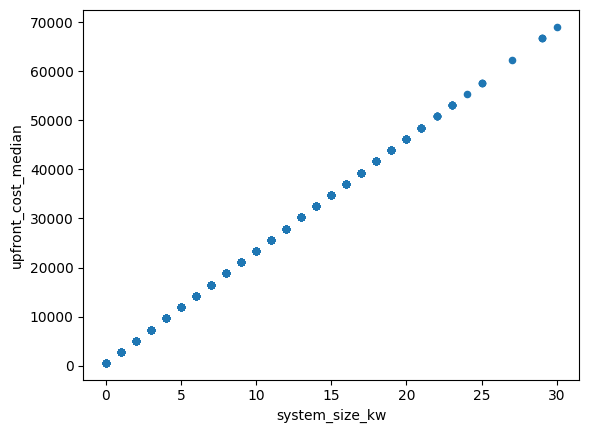

In [0]:
# Join in solar array sizes and make sure they scale in a reasonable way.
solar_configs = spark.table("processed.san_jose_ca_2025_s2.solar_configuration_by_building_solarconfig")

solar_cost_and_size = upfront_costs.where("solar_upgrade_id = 2").join(solar_configs.where("solar_upgrade_id=2"), on="building_id")

solar_cost_and_size.toPandas().plot(kind="scatter", x="system_size_kw", y="upfront_cost_median")

<Axes: title={'center': 'upfront_cost_median'}, xlabel='in_sqft'>

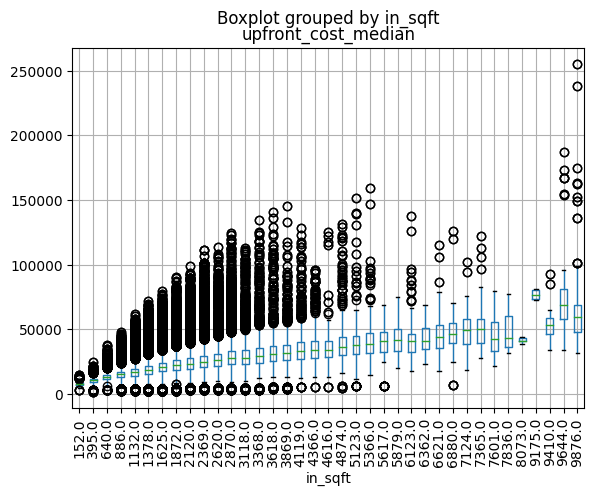

In [0]:
# AHSP costs should be correlated to building size
ashp_cost_and_building_size = upfront_costs.where(
    "appliance_option = 'Mid-Tier Air-Source Heat Pump - ResStock 2025'"
).join(
    building_metadata.where("in_geometry_building_type_acs = 'Single-Family Detached'").select(
        "building_id", "in_geometry_floor_area_bin", "in_sqft"
    ),
    on="building_id",
)

ashp_cost_and_building_size.toPandas().boxplot(column="upfront_cost_median", by="in_sqft", rot=90)

<Axes: xlabel='in_sqft', ylabel='upfront_cost_median'>

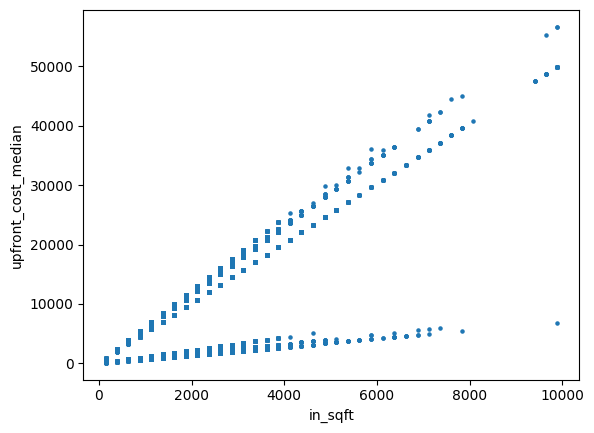

In [0]:
# Weatherization costs should be correlated to building size
ashp_cost_and_building_size = upfront_costs.where(
    "appliance_option = 'Light-touch air sealing and attic insulation Weatherization'"
).join(
    building_metadata.where("in_geometry_building_type_acs = 'Single-Family Detached'").select(
        "building_id", "in_geometry_floor_area_bin", "in_sqft"
    ),
    on="building_id",
)

ashp_cost_and_building_size.toPandas().plot(kind="scatter", x="in_sqft", y="upfront_cost_median", marker='.')

Look at the most and least expensive upgrades and make sure they make sense.

In [0]:
%sql
-- Examine the most expensive upgrades
SELECT * FROM (
  (SELECT *
  FROM t
  ORDER BY upfront_cost_median DESC
  LIMIT 20) as uc
  LEFT JOIN processed.san_jose_ca_2025_s2.building_metadata as bm 
  ON uc.building_id = bm.building_id
);

building_id,upgrade_id,appliance_option,upfront_cost_20percentile,upfront_cost_median,upfront_cost_80percentile,solar_upgrade_id,building_set,building_id,in_ahs_region,in_census_division,in_census_region,in_ashrae_iecc_climate_zone_2004,in_city,county_geoid,puma_geoid,in_state,in_weather_file_city,in_weather_file_latitude,in_weather_file_longitude,in_building_america_climate_zone,in_sqft,in_sqft_bin,in_geometry_floor_area_bin,in_bedrooms,in_vintage,in_orientation,in_geometry_building_type_acs,in_geometry_building_number_units,in_geometry_stories,in_geometry_attic_type,in_geometry_foundation_type,in_geometry_wall_type,in_insulation_ceiling,in_insulation_floor,in_insulation_foundation_wall,in_insulation_rim_joist,in_insulation_roof,in_insulation_slab,in_insulation_wall,in_ducts_leakage,in_ducts_insulation,in_hvac_cooling_type,in_hvac_cooling_efficiency,in_hvac_cooling_partial_space_conditioning,in_heating_fuel,in_hvac_heating_type,in_hvac_heating_appliance_type,in_hvac_has_ducts,in_hvac_shared_system,in_hvac_has_zonal_electric_heating,in_hvac_heating_efficiency,in_hvac_heating_efficiency_nominal_percent,in_hvac_shared_efficiencies,in_hvac_seer_rating,in_hvac_seer2_rating,in_hvac_hspf_rating,in_hvac_hspf2_rating,in_hvac_afue_rating,in_cooling_setpoint,in_cooling_setpoint_has_offset,in_cooling_setpoint_offset_magnitude,in_cooling_setpoint_offset_period,in_heating_setpoint,in_heating_setpoint_has_offset,in_heating_setpoint_offset_magnitude,in_heating_setpoint_offset_period,in_window_wall_ratio_mean,in_infiltration_ach50,in_clothes_dryer_fuel,in_clothes_dryer_usage,in_clothes_washer_efficiency,in_clothes_washer_usage,in_cooking_range_fuel,in_electric_cooking_range_type,in_cooking_range_usage,in_water_heater_efficiency,in_water_heater_fuel,in_water_heater_is_in_unit,in_misc_gas_fireplace,in_misc_gas_grill,in_misc_hot_tub_spa,in_misc_has_pool,in_misc_well_pump,in_income,in_income_bin_midpoint,in_is_rented,in_is_vacant,in_occupants,in_occupants_bin,in_federal_poverty_level,in_area_median_income,in_duct_location,in_water_heater_location,in_energystar_climate_zone_2023,in_roof_area_sqft,in_pv_system_size,in_iso_rto_region,in_electric_panel_breaker_space_total_count,in_electric_panel_service_rating,in_electric_panel_service_rating_bin,in_electric_vehicle_battery,in_electric_vehicle_charge_at_home,in_electric_vehicle_charger,in_electric_vehicle_miles_traveled,in_electric_vehicle_outlet_access,in_electric_vehicle_ownership,in_census_tract
111841,null,Enhanced Weatherization,null,181270.04144894844,null,null,san_jose_ca_2025_s2,111841,Non-CBSA Pacific,Pacific,West,3C,"CA, San Jose",06085,0608510,CA,San Jose Intl Ap,37.37,-121.93,Marine,9876.0,5500+,4000+,1,<1940,Northwest,Single-Family Detached,1,2,Vented Attic,Vented Crawlspace,Wood Frame,R-13,Uninsulated,Uninsulated,Uninsulated,"Unfinished, Uninsulated",None,"Wood Stud, Uninsulated",30,Uninsulated,AC,SEER2 9.5,100%,Natural Gas,Ducted Heating,Furnace,true,None,false,"Fuel Furnace, 92.5% AFUE",92.5,None,null,9.5,null,null,92.5,78F,No,0F,None,60F,No,0F,None,12.0,6,Natural Gas,120,EnergyStar,120,Natural Gas,null,120,Premium,Natural Gas,true,None,None,None,false,None,100000-119999,109999.5,false,false,4,4-5,400%+,80-100%,Crawlspace,Outside,South-Central,5755.6,None,CAISO,27.0,400.0,201+,"Midsize, Battery Electric Vehicle, 300 mile range",80-99%,None,5000,No,No,06085503118
71051,null,Enhanced Weatherization,null,181270.04144894844,null,null,san_jose_ca_2025_s2,71051,Non-CBSA Pacific,Pacific,West,3C,"CA, San Jose",06085,0608508,CA,San Jose Intl Ap,37.37,-121.93,Marine,9876.0,5500+,4000+,4,1970s,East,Single-Family Detached,1,2,Vented Attic,Vented Crawlspace,Wood Frame,R-7,Uninsulated,Uninsulated,Uninsulated,"Unfinished, Uninsulated",None,"Wood Stud, Uninsulated",20,Uninsulated,AC,SEER2 12.4,100%,Natural Gas,Ducted Heating,Furnace,true,None,false,"Fuel Furnace, 80% AFUE",80.0,None,null,12.4,null,null,80.0,80F,No,0F,None,65F,No,0F,None,9.0,3,Natural Gas,100,EnergyStar,100,Natural Gas,null,100,Premiu

In [0]:
%sql
-- Examine the least expensive upgrades
-- These are mostly weatherization for very small homes (<200 sqft), which makes sense
SELECT * FROM (
  (SELECT *
  FROM t
  WHERE upfront_cost_median > 0
  ORDER BY upfront_cost_median
  LIMIT 20) as uc
  LEFT JOIN processed.san_jose_ca_2025_s2.building_metadata as bm 
  ON uc.building_id = bm.building_id
);

building_id,upgrade_id,appliance_option,upfront_cost_20percentile,upfront_cost_median,upfront_cost_80percentile,solar_upgrade_id,building_set,building_id,in_ahs_region,in_census_division,in_census_region,in_ashrae_iecc_climate_zone_2004,in_city,county_geoid,puma_geoid,in_state,in_weather_file_city,in_weather_file_latitude,in_weather_file_longitude,in_building_america_climate_zone,in_sqft,in_sqft_bin,in_geometry_floor_area_bin,in_bedrooms,in_vintage,in_orientation,in_geometry_building_type_acs,in_geometry_building_number_units,in_geometry_stories,in_geometry_attic_type,in_geometry_foundation_type,in_geometry_wall_type,in_insulation_ceiling,in_insulation_floor,in_insulation_foundation_wall,in_insulation_rim_joist,in_insulation_roof,in_insulation_slab,in_insulation_wall,in_ducts_leakage,in_ducts_insulation,in_hvac_cooling_type,in_hvac_cooling_efficiency,in_hvac_cooling_partial_space_conditioning,in_heating_fuel,in_hvac_heating_type,in_hvac_heating_appliance_type,in_hvac_has_ducts,in_hvac_shared_system,in_hvac_has_zonal_electric_heating,in_hvac_heating_efficiency,in_hvac_heating_efficiency_nominal_percent,in_hvac_shared_efficiencies,in_hvac_seer_rating,in_hvac_seer2_rating,in_hvac_hspf_rating,in_hvac_hspf2_rating,in_hvac_afue_rating,in_cooling_setpoint,in_cooling_setpoint_has_offset,in_cooling_setpoint_offset_magnitude,in_cooling_setpoint_offset_period,in_heating_setpoint,in_heating_setpoint_has_offset,in_heating_setpoint_offset_magnitude,in_heating_setpoint_offset_period,in_window_wall_ratio_mean,in_infiltration_ach50,in_clothes_dryer_fuel,in_clothes_dryer_usage,in_clothes_washer_efficiency,in_clothes_washer_usage,in_cooking_range_fuel,in_electric_cooking_range_type,in_cooking_range_usage,in_water_heater_efficiency,in_water_heater_fuel,in_water_heater_is_in_unit,in_misc_gas_fireplace,in_misc_gas_grill,in_misc_hot_tub_spa,in_misc_has_pool,in_misc_well_pump,in_income,in_income_bin_midpoint,in_is_rented,in_is_vacant,in_occupants,in_occupants_bin,in_federal_poverty_level,in_area_median_income,in_duct_location,in_water_heater_location,in_energystar_climate_zone_2023,in_roof_area_sqft,in_pv_system_size,in_iso_rto_region,in_electric_panel_breaker_space_total_count,in_electric_panel_service_rating,in_electric_panel_service_rating_bin,in_electric_vehicle_battery,in_electric_vehicle_charge_at_home,in_electric_vehicle_charger,in_electric_vehicle_miles_traveled,in_electric_vehicle_outlet_access,in_electric_vehicle_ownership,in_census_tract
147366,null,Light-touch air sealing Weatherization,null,104.74450794625302,null,null,san_jose_ca_2025_s2,147366,Non-CBSA Pacific,Pacific,West,3C,"CA, San Jose",06085,0608512,CA,San Jose Intl Ap,37.37,-121.93,Marine,152.0,0-1499,0-1499,1,1960s,South,Single-Family Detached,1,1,Vented Attic,Slab,Wood Frame,R-13,None,None,None,"Unfinished, Uninsulated",Uninsulated,"Wood Stud, Uninsulated",20,R-4,None,null,None,Natural Gas,Ducted Heating,Furnace,true,None,false,"Fuel Furnace, 92.5% AFUE",92.5,None,null,null,null,null,92.5,78F,No,0F,None,68F,Yes,12F,Night +1h,15.0,8,Natural Gas,100,EnergyStar,100,Electricity,Resistance,100,Standard,Natural Gas,true,None,None,None,false,Typical Efficiency,100000-119999,109999.5,false,false,2,2-3,400%+,80-100%,Attic,Outside,South-Central,170.0,None,CAISO,14.0,100.0,100,"Compact, Battery Electric Vehicle, 300 mile range",100%,None,7000,Yes,No,06085512045
6637,null,Light-touch air sealing Weatherization,null,104.74450794625302,null,null,san_jose_ca_2025_s2,6637,Non-CBSA Pacific,Pacific,West,3C,"CA, San Jose",06085,0608504,CA,San Jose Intl Ap,37.37,-121.93,Marine,152.0,0-1499,0-1499,1,1960s,South,Single-Family Detached,1,1,Vented Attic,Slab,Wood Frame,R-19,None,None,None,"Unfinished, Uninsulated",Uninsulated,"Wood Stud, Uninsulated",10,R-4,AC,SEER2 12.4,100%,Natural Gas,Ducted Heating,Furnace,true,None,false,"Fuel Furnace, 80% AFUE",80.0,None,null,12.4,null,null,80.0,76F,No,0F,None,65F,No,0F,None,18.0,8,Electricity,100,Standard,100,Electricity,Resistance,100,Premium,Natural Gas,true,

In [0]:
%sql
-- Examine the least expensive ASHP upgrades
-- These are from small homes (<900 sqft) with no heating demand
-- These appear to be underpriced, possibly because we're using the cost of a 0-ton HP.
SELECT * FROM (
  (SELECT *
  FROM t
  WHERE upfront_cost_median > 0
  and appliance_option = "Mid-Tier Air-Source Heat Pump - ResStock 2025"
  ORDER BY upfront_cost_median
  LIMIT 20) as uc
  LEFT JOIN processed.san_jose_ca_2025_s2.building_metadata as bm 
  ON uc.building_id = bm.building_id
);

building_id,upgrade_id,appliance_option,upfront_cost_20percentile,upfront_cost_median,upfront_cost_80percentile,solar_upgrade_id,building_set,building_id,in_ahs_region,in_census_division,in_census_region,in_ashrae_iecc_climate_zone_2004,in_city,county_geoid,puma_geoid,in_state,in_weather_file_city,in_weather_file_latitude,in_weather_file_longitude,in_building_america_climate_zone,in_sqft,in_sqft_bin,in_geometry_floor_area_bin,in_bedrooms,in_vintage,in_orientation,in_geometry_building_type_acs,in_geometry_building_number_units,in_geometry_stories,in_geometry_attic_type,in_geometry_foundation_type,in_geometry_wall_type,in_insulation_ceiling,in_insulation_floor,in_insulation_foundation_wall,in_insulation_rim_joist,in_insulation_roof,in_insulation_slab,in_insulation_wall,in_ducts_leakage,in_ducts_insulation,in_hvac_cooling_type,in_hvac_cooling_efficiency,in_hvac_cooling_partial_space_conditioning,in_heating_fuel,in_hvac_heating_type,in_hvac_heating_appliance_type,in_hvac_has_ducts,in_hvac_shared_system,in_hvac_has_zonal_electric_heating,in_hvac_heating_efficiency,in_hvac_heating_efficiency_nominal_percent,in_hvac_shared_efficiencies,in_hvac_seer_rating,in_hvac_seer2_rating,in_hvac_hspf_rating,in_hvac_hspf2_rating,in_hvac_afue_rating,in_cooling_setpoint,in_cooling_setpoint_has_offset,in_cooling_setpoint_offset_magnitude,in_cooling_setpoint_offset_period,in_heating_setpoint,in_heating_setpoint_has_offset,in_heating_setpoint_offset_magnitude,in_heating_setpoint_offset_period,in_window_wall_ratio_mean,in_infiltration_ach50,in_clothes_dryer_fuel,in_clothes_dryer_usage,in_clothes_washer_efficiency,in_clothes_washer_usage,in_cooking_range_fuel,in_electric_cooking_range_type,in_cooking_range_usage,in_water_heater_efficiency,in_water_heater_fuel,in_water_heater_is_in_unit,in_misc_gas_fireplace,in_misc_gas_grill,in_misc_hot_tub_spa,in_misc_has_pool,in_misc_well_pump,in_income,in_income_bin_midpoint,in_is_rented,in_is_vacant,in_occupants,in_occupants_bin,in_federal_poverty_level,in_area_median_income,in_duct_location,in_water_heater_location,in_energystar_climate_zone_2023,in_roof_area_sqft,in_pv_system_size,in_iso_rto_region,in_electric_panel_breaker_space_total_count,in_electric_panel_service_rating,in_electric_panel_service_rating_bin,in_electric_vehicle_battery,in_electric_vehicle_charge_at_home,in_electric_vehicle_charger,in_electric_vehicle_miles_traveled,in_electric_vehicle_outlet_access,in_electric_vehicle_ownership,in_census_tract
141311,20.07.2024,Mid-Tier Air-Source Heat Pump - ResStock 2025,908.2570139967436,1875.591383211431,5165.907789334902,null,san_jose_ca_2025_s2,141311,Non-CBSA Pacific,Pacific,West,3C,"CA, San Jose",06085,0608514,CA,San Jose Intl Ap,37.37,-121.93,Marine,395.0,0-1499,0-1499,1,1960s,East,Single-Family Detached,1,1,Vented Attic,Vented Crawlspace,Wood Frame,Uninsulated,Uninsulated,Uninsulated,Uninsulated,"Unfinished, Uninsulated",None,"Wood Stud, Uninsulated",30,Uninsulated,AC,SEER2 9.5,100%,None,None,None,true,None,false,None,null,None,null,9.5,null,null,null,72F,No,0F,None,65F,Yes,12F,Night -3h,9.0,25,Natural Gas,100,Standard,100,Natural Gas,null,100,Premium,Natural Gas,true,None,None,None,false,None,25000-29999,27499.5,true,false,1,1,200-300%,30-60%,Crawlspace,Living Space,South-Central,709.9,None,CAISO,29.0,125.0,125,"Compact, Battery Electric Vehicle, 200 mile range",100%,None,17000,Yes,No,06085503506
141311,20.07.TMY3,Mid-Tier Air-Source Heat Pump - ResStock 2025,908.2570139967436,1875.591383211431,5165.907789334902,null,san_jose_ca_2025_s2,141311,Non-CBSA Pacific,Pacific,West,3C,"CA, San Jose",06085,0608514,CA,San Jose Intl Ap,37.37,-121.93,Marine,395.0,0-1499,0-1499,1,1960s,East,Single-Family Detached,1,1,Vented Attic,Vented Crawlspace,Wood Frame,Uninsulated,Uninsulated,Uninsulated,Uninsulated,"Unfinished, Uninsulated",None,"Wood Stud, Uninsulated",30,Uninsulated,AC,SEER2 9.5,100%,None,None,None,true,None,false,None,null,None,null,9.5,null,null,null,72F,No,0F,None,65F,Yes,12F,Night -3h,9.0,25,Natural Ga